In [1]:
# !pip install umap-learn 

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

import umap   

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

## 0. Setup: install and get the data

In [2]:
cells = pd.read_csv("./holiday_versions/cells_with_holiday.csv")
GENES = list(cells.columns[4:])

print(cells.shape)
print(cells.groupby(["experiment", "timepoint"]).size())
cells.head()

(14970, 64)
experiment   timepoint
docetaxel    A            3000
             B            1707
osimertinib  A            3000
             B            1419
untreated    A            3000
             B            2844
dtype: int64


,cell_id,experiment,timepoint,lineage_tag,CCND1,CDK6,MYC,E2F1,CDT1,PCNA,...,ISG15,IFIT1,IFIT3,MX1,OAS1,RPL13,RPS19,RPS27A,RPL32,RPS12
0,cell_o_00000,osimertinib,A,tago-02305,11,9,4,5,5,3,...,3,1,0,0,1,7,7,7,4,2
1,cell_o_00001,osimertinib,B,tago-01560,2,3,0,0,5,2,...,2,3,2,0,1,11,18,18,34,20
2,cell_o_00002,osimertinib,A,tago-02253,3,6,16,12,4,5,...,2,1,2,0,0,8,2,3,6,8
3,cell_o_00003,osimertinib,A,tago-01478,1,2,0,0,2,9,...,2,2,0,1,2,4,9,14,7,3
4,cell_o_00004,osimertinib,A,tago-02626,15,20,34,22,18,5,...,0,0,0,0,7,8,8,9,7,4


Each row is one cell. `experiment` is which drug the culture got, `timepoint` is `A` (before) or `B` (after one cycle), `lineage_tag` is the barcode (matching 2 cells between A and B), and the remaining 60 columns are counts of RNA molecules per gene.

<div class='alert alert-info'>
<b>Before you go on:</b> why are there fewer cells at time point B than at A?
</div>

*Answer the question above.*

## 1 · Decide the states

A Markov chain needs a **state space**: the finite list of values the process can take. Some computational biology tools consider each cell to be it's own state, so the state space is as big as your sample. You should have a good idea by now why that might not be the best idea.

<div class='alert alert-info'> <b>Question:</b>Why would it generally be a better idea to cluster cells into groups before assigning cell states, rather than considering each cell to be its own state? </div>

*Answer here.*

Instead, we'll consider how to group the cells. There is a standard single-cell recipe, which is given to you below:

1. **Normalize** each cell to the same total count (cells are sequenced to different depths), then take `log1p`.
2. **PCA** on the normalized RNA counts, which are a measure of cell identity (phenotype) 
3. **Cluster** in PCA space with k-means.
4. **UMAP** to 2-D, *only for looking at*. UMAP distorts distances, so cluster in PCA space and draw in UMAP space.

**We embed every cell from both time points and both drugs together**, so that "cluster 2" means the same kind of cell everywhere. If you clustered each time point separately, the labels would not line up and you could not count transitions.

In [3]:
X = cells[GENES].to_numpy(dtype=float)
X = np.log1p(X / X.sum(axis=1, keepdims=True) * 1e4)   # normalize, log
X = (X - X.mean(axis=0)) / X.std(axis=0)               # standardize each gene

pcs = PCA(n_components=10, random_state=0).fit_transform(X)
emb = umap.UMAP(random_state=0).fit_transform(pcs)  
cells["x"], cells["y"] = emb[:, 0], emb[:, 1]

/opt/anaconda3/envs/uu/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Now cluster. `K` is the number of states you believe are in the data. After trying a few values for K and looking at the PCA and UMAP, you will notice that K=7 is a good fit.

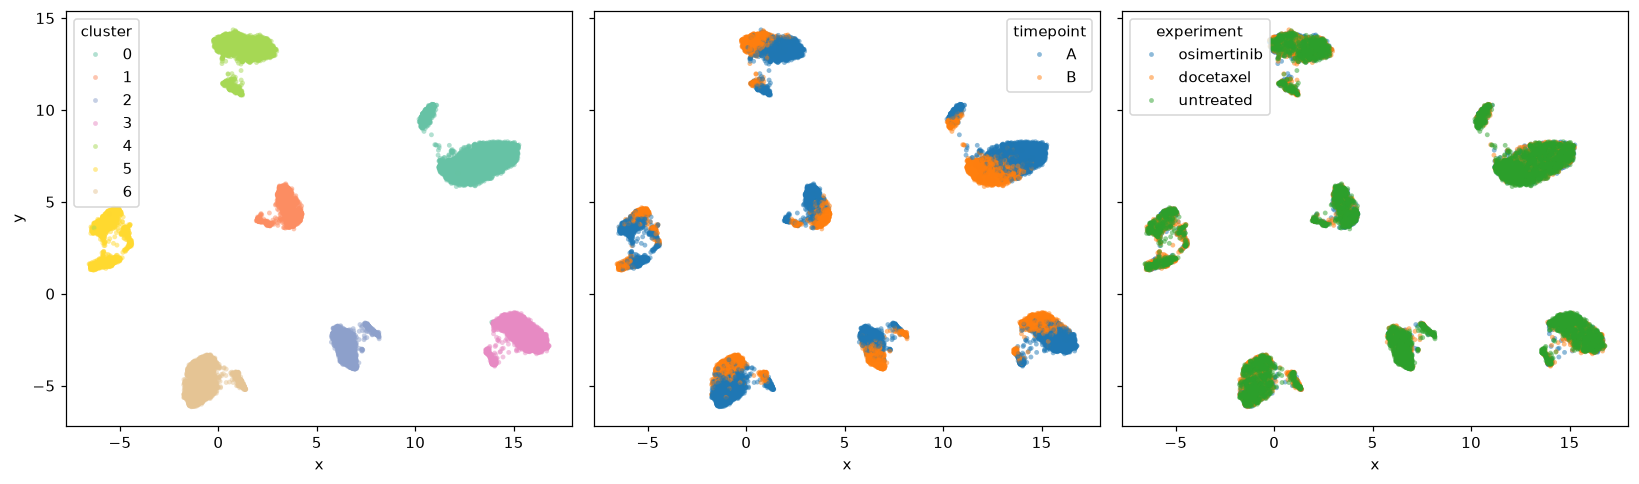

In [4]:
# Run KMeans' fit_predict method on pcs, and then plot using UMAP
# Do the clusters separate well?
import seaborn as sns
K = 7
cells["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(pcs)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "x", y ="y", hue = "cluster", ax = axes[0], palette = "Set2", s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "x", y ="y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "x", y ="y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

In [5]:
pd.crosstab([cells.experiment, cells.timepoint], cells.cluster)

cluster                  0    1    2    3    4    5    6
experiment  timepoint                                   
docetaxel   A          736  290  284  440  477  319  454
            B          336   29  106  160  328  254  494
osimertinib A          751  279  280  454  455  312  469
            B          212  279   66   78  417  285   82
untreated   A          736  306  331  441  441  291  454
            B          932  251  451  595  209  159  247

**Look at the table.** Compare time point A and time point B for each drug. Which states grew and which shrank? Can you already tell, from these rows alone, *where* the cells that left each state went?

You can't: the table gives the two marginal distributions, not the transitions. Many different transition patterns produce the same before/after totals. That is what the lineage tags are for.

### Name the clusters

We can label each cluster with a name, since we know which genes each kind of cell expresses. Each state has one **marker gene** that is high only in that state:

| high gene | state | what the cells are doing |
|---|---|---|
| CCND1 | **S-G1** | sensitive, resting before copying DNA |
| PCNA | **S-syn** | sensitive, copying DNA |
| MKI67 | **S-G2M** | sensitive, dividing |
| NEAT1 | **P** | early drug-tolerant persister |
| HLA-A | **NCP** | non-cycling persister |
| GSTM3 | **CP** | cycling persister (keeps dividing on osimertinib) |
| ABCB1 | **MDR** | drug pumps on (multidrug resistant) |

The code below colours the UMAP by each marker gene, then names every cluster after the marker gene that is highest in it. From here on we use these names instead of cluster numbers.

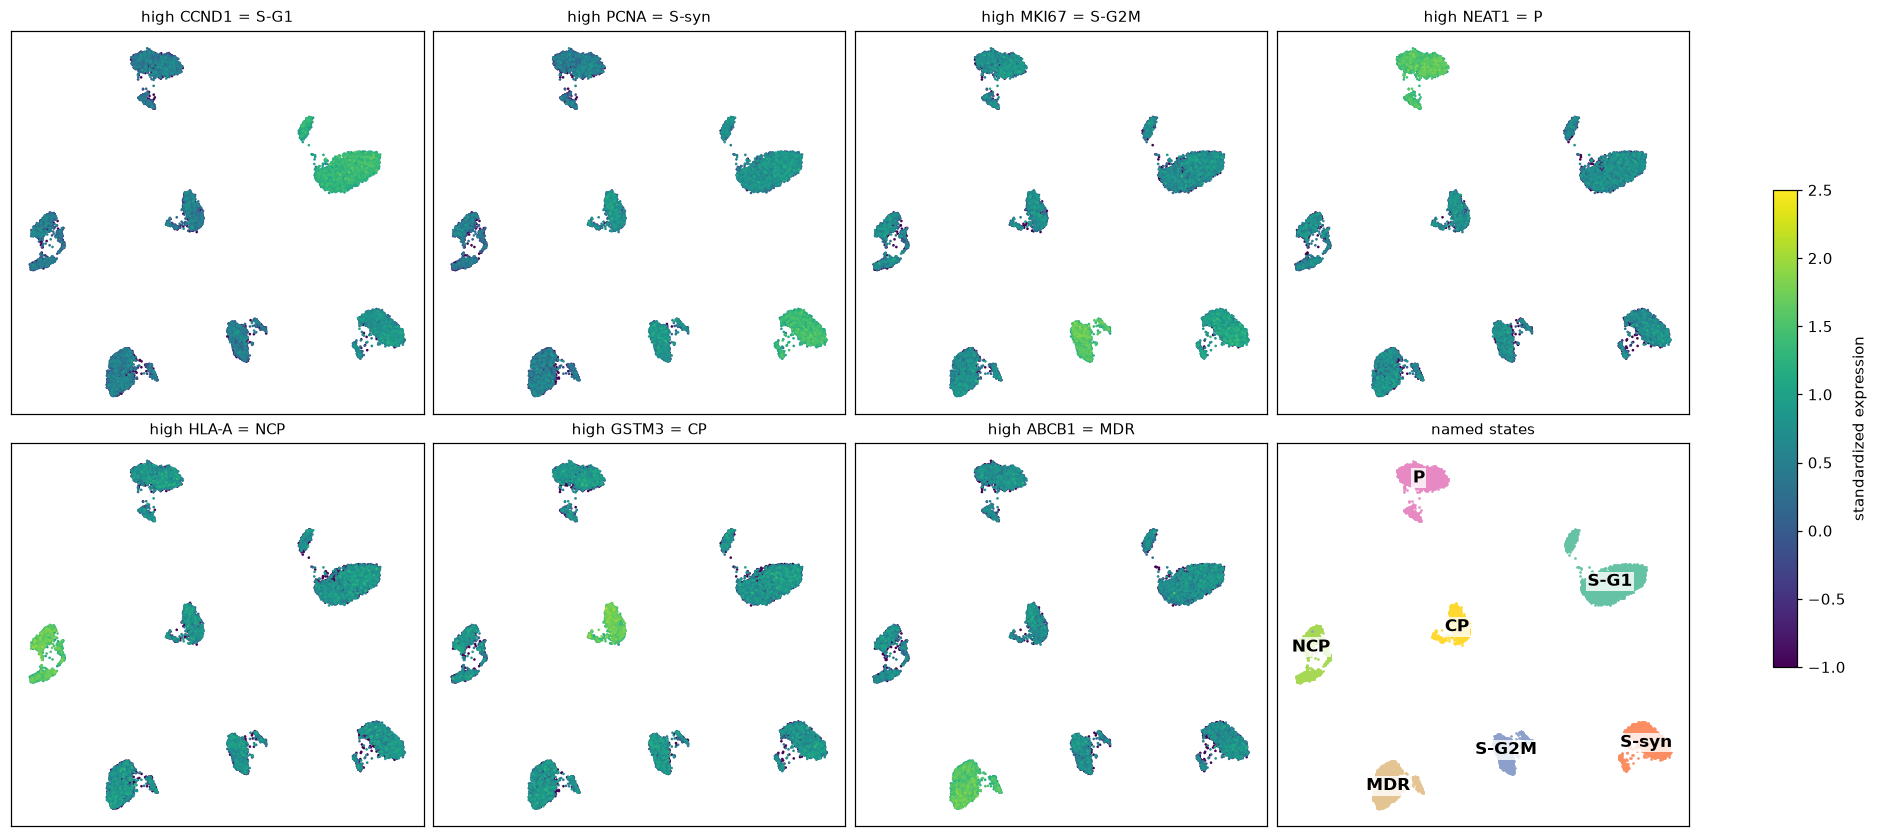

cluster -> state: {0: 'S-G1', 1: 'CP', 2: 'S-G2M', 3: 'S-syn', 4: 'P', 5: 'NCP', 6: 'MDR'}
states with no cluster: none


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR
cluster,,,,,,,
0,1.03,0.20,-0.24,-0.22,-0.15,-0.15,-0.22
1,-0.45,0.19,-0.28,-0.19,-0.15,1.40,-0.21
2,-0.49,0.15,1.29,-0.26,-0.17,-0.13,-0.21
3,0.25,1.07,0.46,-0.25,-0.19,-0.16,-0.23
4,-0.49,-0.56,-0.24,1.27,-0.15,-0.14,-0.22
5,-0.47,-0.58,-0.32,-0.25,1.34,-0.20,-0.24
6,-0.49,-0.59,-0.27,-0.24,-0.17,-0.12,1.29


In [6]:
MARKERS = {"S-G1": "CCND1", "S-syn": "PCNA", "S-G2M": "MKI67", "P": "NEAT1",
           "NCP": "HLA-A", "CP": "GSTM3", "MDR": "ABCB1"}
STATE_ORDER = list(MARKERS)                       # sensitive states first, then persisters, then resistant

# UMAP coloured by each marker gene (standardized log expression, from X above)
expr = pd.DataFrame(X, columns=GENES)
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True, sharey=True, constrained_layout=True)
for ax, (state, gene) in zip(axes.flat, MARKERS.items()):
    order = np.argsort(expr[gene].to_numpy())     # draw high-expressing cells on top
    sc = ax.scatter(cells.x.to_numpy()[order], cells.y.to_numpy()[order], c=expr[gene].to_numpy()[order],
                    cmap="viridis", vmin=-1, vmax=2.5, s=3, linewidths=0)
    ax.set_title(f"high {gene} = {state}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axes, shrink=0.6, label="standardized expression")

# Name each cluster after the marker gene that is highest in it
cluster_means = expr[list(MARKERS.values())].groupby(cells["cluster"]).mean()
cluster_means.columns = list(MARKERS)             # rename gene columns to state names
cluster_to_state = cluster_means.idxmax(axis=1).to_dict()
cells["state"] = cells["cluster"].map(cluster_to_state)

STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"

ax = axes.flat[-1]
for state, sub in cells.groupby("state"):
    ax.scatter(sub.x, sub.y, s=3, color=STATE_COLORS[state], linewidths=0)
    ax.text(sub.x.median(), sub.y.median(), state, ha="center", va="center", fontsize=11,
            fontweight="bold", bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1))
ax.set_title("named states", fontsize=10)
plt.show()

missing = [s for s in STATE_ORDER if s not in cluster_to_state.values()]
print("cluster -> state:", cluster_to_state)
print("states with no cluster:", missing or "none")
cluster_means.round(2)

In [7]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,NaN
1,tago-02253,S-G1,NaN
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [11]:
cells_small = cells[["experiment","timepoint", "lineage_tag","x","y","state"]]

In [12]:
cells_small.columns = ["experiment","timepoint", "lineage_tag","umap_x","umap_y","state"]

In [13]:
cells_small.to_csv("cell_data.csv")